In [3]:
# imports
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix,classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [5]:
#load the data
data = pd.read_csv('creditcard.csv')
print(data.head())

   Time        V1        V2        V3        V4        V5  ...       V25       V26       V27       V28  Amount  Class
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  ...  0.128539 -0.189115  0.133558 -0.021053  149.62      0
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018  ...  0.167170  0.125895 -0.008983  0.014724    2.69      0
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  ... -0.327642 -0.139097 -0.055353 -0.059752  378.66      0
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  ...  0.647376 -0.221929  0.062723  0.061458  123.50      0
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  ... -0.206010  0.502292  0.219422  0.215153   69.99      0

[5 rows x 31 columns]


In [13]:
X = data.drop('Class',axis=1)
y = data['Class']

#split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

x_train_normal = X_train[y_train==0]


scaler = StandardScaler()
x_train_normal = scaler.fit_transform(x_train_normal)
x_test = scaler.transform(X_test)

In [14]:
#autoencoder
autoencoder = Sequential([
    Input(shape=(x_train_normal.shape[1],)),
    #encoder
    Dense(32,activation='relu'),
    Dense(16,activation='relu'),
    Dense(8,activation='relu'),

    #decoder
    Dense(16,activation='relu'),
    Dense(32,activation='relu'),
    
    Dense(x_train_normal.shape[1],activation='linear')
])

In [15]:
#compile
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

#fit
history = autoencoder.fit(
    x_train_normal,x_train_normal,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/10
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 13s 3ms/step - loss: 0.6219 - mae: 0.5251 - val_loss: 0.5150 - val_mae: 0.4916
Epoch 2/10
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 21s 3ms/step - loss: 0.4498 - mae: 0.4546 - val_loss: 0.4038 - val_mae: 0.4393
Epoch 3/10
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 21s 3ms/step - loss: 0.4064 - mae: 0.4336 - val_loss: 0.3777 - val_mae: 0.4250
Epoch 4/10
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 21s 3ms/step - loss: 0.3812 - mae: 0.4201 - val_loss: 0.3535 - val_mae: 0.4111
Epoch 5/10
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - loss: 0.3535 - mae: 0.4036 - val_loss: 0.3396 - val_mae: 0.3983
Epoch 6/10
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 21s 3ms/step - loss: 0.3376 - mae: 0.3923 - val_loss: 0.3222 - val_mae: 0.3873
Epoch 7/10
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - loss: 0.3282 - mae: 0.3852 - val_loss: 0.3145 - val_mae: 0.3795
Epoch 8/10
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - loss: 0.3201 - mae: 0.3798 - val_loss: 0.3307 - val_mae: 0.3884
Epoch 9/10
3199/3199 ━━━━━━━━━━━

In [19]:
train_pred = autoencoder.predict(x_train_normal)
train_error = np.mean(np.square(x_train_normal-train_pred),axis=1)


#threshold
threshold = np.percentile(train_error,95)

test_pred = autoencoder.predict(x_test)
test_error = np.mean(np.square(x_test-test_pred),axis=1)

y_pred = (test_error > threshold).astype(int)

print(y_pred)

7108/7108 ━━━━━━━━━━━━━━━━━━━━ 19s 3ms/step
1781/1781 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step
[0 0 1 ... 0 0 0]


In [20]:
#confusion matrix
print("confusion matrix",confusion_matrix(y_test,y_pred))
print("classifican report",classification_report(y_test,y_pred))

confusion matrix [[54015  2849]
 [   14    84]]
classifican report               precision    recall  f1-score   support

           0       1.00      0.95      0.97     56864
           1       0.03      0.86      0.06        98

    accuracy                           0.95     56962
   macro avg       0.51      0.90      0.51     56962
weighted avg       1.00      0.95      0.97     56962



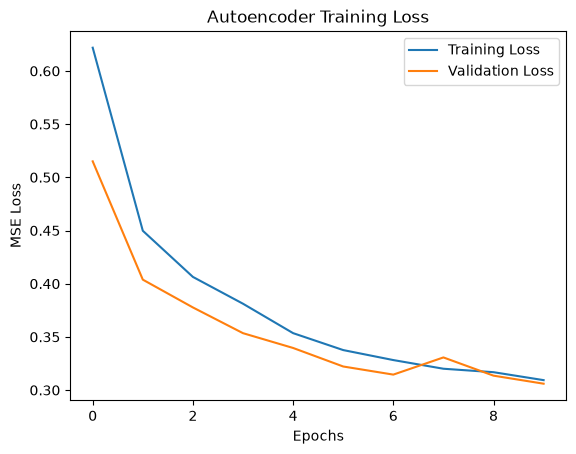

In [22]:
#plot
import matplotlib.pyplot as plt
# 15. Plot Training Loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Autoencoder Training Loss')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.legend()
plt.show()

In [ ]:

# 3A. Credit Card Fraud Detection using Autoencoder

# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense


# 1. Load the dataset
data = pd.read_csv('creditcard.csv')

print(data.head())
print("Dataset shape:", data.shape)


# 2. Separate features and target
X = data.drop('Class', axis=1)  # Transaction features
y = data['Class']               # 0 = Normal, 1 = Fraud


# 3. Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 4. Keep only normal transactions for training
x_train_normal = X_train[y_train == 0]

print("Normal training transactions:", x_train_normal.shape[0])


# 5. Scale the features
scaler = StandardScaler()

# Fit the scaler only on normal training data
x_train_normal = scaler.fit_transform(x_train_normal)

# Transform the complete test data using the same scaler
x_test = scaler.transform(X_test)


# 6. Build the autoencoder
autoencoder = Sequential([
    Input(shape=(x_train_normal.shape[1],)),

    # Encoder: compress the input features
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),

    # Decoder: reconstruct the original features
    Dense(16, activation='relu'),
    Dense(32, activation='relu'),
    Dense(x_train_normal.shape[1], activation='linear')
])


# 7. Compile the model
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)


# 8. Train the autoencoder using normal transactions only
history = autoencoder.fit(
    x_train_normal,
    x_train_normal,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    shuffle=True
)


# 9. Calculate reconstruction errors on normal training data
train_pred = autoencoder.predict(x_train_normal, verbose=0)

train_error = np.mean(
    np.square(x_train_normal - train_pred),
    axis=1
)


# 10. Set the threshold using the 95th percentile
threshold = np.percentile(train_error, 95)

print("Reconstruction error threshold:", threshold)


# 11. Reconstruct the test transactions
test_pred = autoencoder.predict(x_test, verbose=0)

# Calculate reconstruction error for each test transaction
test_error = np.mean(
    np.square(x_test - test_pred),
    axis=1
)


# 12. Detect fraud
# Error above threshold = Fraud (1)
# Error at or below threshold = Normal (0)
y_pred = (test_error > threshold).astype(int)

print("\nFirst 20 predictions:")
print(y_pred[:20])


# 13. Evaluate the model
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Normal', 'Fraud'],
    zero_division=0
))


# 14. Plot training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Autoencoder Training Loss')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.legend()
plt.show()
